<h1>Содержание<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#ОПИСАНИЕ-ПРОЕКТА" data-toc-modified-id="ОПИСАНИЕ-ПРОЕКТА-1"><span class="toc-item-num">1&nbsp;&nbsp;</span><span style="color: #8dbf78">ОПИСАНИЕ ПРОЕКТА</span></a></span><ul class="toc-item"><li><span><a href="#Импорты" data-toc-modified-id="Импорты-1.1"><span class="toc-item-num">1.1&nbsp;&nbsp;</span>Импорты</a></span></li><li><span><a href="#Загрузка-данных" data-toc-modified-id="Загрузка-данных-1.2"><span class="toc-item-num">1.2&nbsp;&nbsp;</span>Загрузка данных</a></span></li><li><span><a href="#Распределение-целевого-признака" data-toc-modified-id="Распределение-целевого-признака-1.3"><span class="toc-item-num">1.3&nbsp;&nbsp;</span>Распределение целевого признака</a></span></li></ul></li><li><span><a href="#-ПОДГОТОВКА-ДАННЫХ" data-toc-modified-id="-ПОДГОТОВКА-ДАННЫХ-2"><span class="toc-item-num">2&nbsp;&nbsp;</span><span style="color: #8dbf78"> ПОДГОТОВКА ДАННЫХ</span></a></span><ul class="toc-item"><li><span><a href="#Очистка-текста" data-toc-modified-id="Очистка-текста-2.1"><span class="toc-item-num">2.1&nbsp;&nbsp;</span>Очистка текста</a></span></li><li><span><a href="#Лемматизация" data-toc-modified-id="Лемматизация-2.2"><span class="toc-item-num">2.2&nbsp;&nbsp;</span>Лемматизация</a></span></li><li><span><a href="#-вывод-по-разделу" data-toc-modified-id="-вывод-по-разделу-2.3"><span class="toc-item-num">2.3&nbsp;&nbsp;</span><span style="color: #8dbf78"> вывод по разделу</span></a></span></li></ul></li><li><span><a href="#ОБУЧЕНИЕ" data-toc-modified-id="ОБУЧЕНИЕ-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>ОБУЧЕНИЕ</a></span><ul class="toc-item"><li><span><a href="#Разделение-данных" data-toc-modified-id="Разделение-данных-3.1"><span class="toc-item-num">3.1&nbsp;&nbsp;</span>Разделение данных</a></span></li><li><span><a href="#Пайплайн" data-toc-modified-id="Пайплайн-3.2"><span class="toc-item-num">3.2&nbsp;&nbsp;</span>Пайплайн</a></span></li><li><span><a href="#Результаты-обучения-модели" data-toc-modified-id="Результаты-обучения-модели-3.3"><span class="toc-item-num">3.3&nbsp;&nbsp;</span>Результаты обучения модели</a></span></li><li><span><a href="#Проверка-лучшей-модели-на-тестовой-выборке" data-toc-modified-id="Проверка-лучшей-модели-на-тестовой-выборке-3.4"><span class="toc-item-num">3.4&nbsp;&nbsp;</span>Проверка лучшей модели на тестовой выборке</a></span></li><li><span><a href="#Интерпритация-результатов" data-toc-modified-id="Интерпритация-результатов-3.5"><span class="toc-item-num">3.5&nbsp;&nbsp;</span>Интерпритация результатов</a></span></li><li><span><a href="#-вывод-по-разделу" data-toc-modified-id="-вывод-по-разделу-3.6"><span class="toc-item-num">3.6&nbsp;&nbsp;</span><span style="color: #8dbf78"> вывод по разделу</span></a></span></li></ul></li><li><span><a href="#-ВЫВОДЫ" data-toc-modified-id="-ВЫВОДЫ-4"><span class="toc-item-num">4&nbsp;&nbsp;</span><span style="color: #8dbf78"> ВЫВОДЫ</span></a></span></li></ul></div>

<div style="background-color: white; border: 2px solid #8DBF78; border-radius: 0px; padding: 15px 25px; display: inline-block; color: black;">
    
<div style="border-left: 4px solid #F39C12; padding-left: 15px; margin: 15px 0;"> 
  
--- 
    
#  ПРОЕКТ: Классификация комментариев для интернет-магазина
    
---

<div style="background-color: white; border: 5px solid #F39C12; border-radius: 10px; padding: 15px 25px; display: inline-block; color: black;">

## <span style="color:#8DBF78">ОПИСАНИЕ ПРОЕКТА

---

**з а к а з ч и к**: Интернет-магазин «Викишоп»

**ц е л ь**: *Разработать инструмент для автоматической модерации комментариев*, который будет находить токсичные высказывания и отправлять их на проверку модератору.
    
**з а д а ч и**:

<span style="color:#8DBF78">
    
**1.** <span style="color:black">Загрузить и подготовить данные (очистка текста, лемматизация).

**2.** <span style="color:black">Векторизовать тексты (TF-IDF или эмбеддинги).

**3.** <span style="color:black">Обучить модель классификации для разделения комментариев на позитивные и негативные.

**4.** <span style="color:black">Достичь целевого значения метрики F1.

**5.** <span style="color:black">Сделать выводы по результатам работы модели.

---

<span style="color:#8DBF78">ОПИСАНИЕ ДАННЫХ

- **`text`** — <span style="color:black">текст комментария.
- **`toxic`** — <span style="color:black">целевой признак (1 — токсичный комментарий, 0 — нетоксичный).

---

<span style="color:#8DBF78">КРИТЕРИИ УСПЕХА

<span style="color:black">Значение метрики **F1** на тестовой выборке должно быть **не меньше 0.75**.

</div>

<div style="border-left: 4px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Импорты

In [1]:
# Установка библиотек
!pip install -q shap
!pip install phik -q

In [2]:
# Стандартные библиотеки
import time
import re
import warnings
warnings.filterwarnings('ignore')

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Работа с данными
import pandas as pd
import numpy as np

# NLTK для обработки текста
import nltk
from nltk.corpus import stopwords
from nltk.corpus import wordnet as wn
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Scikit-learn - preprocessing и feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline

# Scikit-learn - models
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.svm import LinearSVC

# Scikit-learn - metrics
from sklearn.metrics import (
                              f1_score, make_scorer,
                              classification_report, confusion_matrix,
                              precision_score, recall_score, accuracy_score
                            )

# Для прогресс-бара
from tqdm import tqdm
tqdm.pandas()

# Константа
RANDOM_STATE = 42

# Загрузка данных NLTK
nltk.download('stopwords') # для удаления предлогов, союзов, местоимений
nltk.download('wordnet') # для приведения слов к начальной форме
nltk.download('punkt') # для правильного разделения текста на токены
nltk.download('averaged_perceptron_tagger') # для правильной лемматизации (глаголы/существительные)

<div style="border-left: 4px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Загрузка данных

In [4]:
# Загружаем данные
df = pd.read_csv('/datasets/toxic_comments.csv', index_col=[0])

In [5]:
def head_and_info_display(df, n=5, show_shape=True, show_dtypes=True):
    '''
    ИНФОРМАЦИЯ О ДАТАФРЕЙМЕ - Выводит информацию о загруженных данных
    
    Параметры:
    df - DataFrame для анализа
    n - Количество строк
    '''
    print('~' * 23)
    print('ИНФОРМАЦИЯ О ДАТАФРЕЙМЕ')
    print('~' * 23)
    
    # 1. Размер данных
    print(f'Форма данных: {df.shape[0]} строк, {df.shape[1]} столбцов')
    
    # Информация об индексе
    print("\nИНФОРМАЦИЯ ОБ ИНДЕКСЕ:")
    print("-" * 40)
    idx = df.index
    if isinstance(idx, pd.MultiIndex):
        print(f"Тип: MultiIndex\nУровни: {list(idx.names)}\nУникальных комбинаций: {idx.nunique()}")
    else:
        print(f"Тип: {type(idx).__name__}\nИмя: {idx.name}\nУникальных: {idx.nunique()}")
    
    # Проверка монотонности индекса
    if hasattr(idx, 'is_monotonic_increasing'):
        inc = idx.is_monotonic_increasing
        print(f"Индекс монотонно возрастает: {inc}")
        if not inc and hasattr(idx, 'is_monotonic_decreasing'):
            print(f"Индекс монотонно убывает: {idx.is_monotonic_decreasing}")
    
    # 2. Первые n строк
    print(f"\nПервые {n} строк:")
    print("-" * 15)
    display(df.head(n))
    
    # 3. Общая информация
    print(f"\nОбщая информация:")
    print("-" * 17)
    df.info()
    
    # 4. Пропущенные значения
    print(f"\nПРОПУЩЕННЫЕ ЗНАЧЕНИЯ:")
    print("-" * 30)
    
    # Вычисляем количество и процент пропусков по столбцам
    missing_values = df.isnull().sum()
    total_rows = df.shape[0]
    
    # Фильтруем только столбцы с пропусками
    columns_with_missing = missing_values[missing_values > 0]
    
    if len(columns_with_missing) == 0:
        print('Пропущенных значений нет')
    else:
        print(f'Столбцы с пропущенными значениями ({len(columns_with_missing)} из {df.shape[1]}):')
        
        # Создаем DataFrame для красивого отображения
        missing_df = pd.DataFrame({
                                    'Столбец': columns_with_missing.index,
                                    'Кол-во пропусков': columns_with_missing.values,
                                    '% пропусков': (columns_with_missing.values / total_rows * 100).round(2)
                                 })
        display(missing_df)
        
        print(f'Всего пропусков в датафрейме: {missing_values.sum()}')
        print(f'Средний % пропусков: {(missing_values.sum() / (total_rows * df.shape[1]) * 100).round(2)}%')
       
    # 5. Дубликаты строк
    print(f'\nПРОВЕРКА ЯВНЫХ ДУБЛИКАТОВ:')
    print("-" * 20)
    duplicates_count = df.duplicated().sum()
    if duplicates_count == 0:
        print('Дубликатов строк нет')
    else:
        print(f'Найдено {duplicates_count} дубликатов строк ({duplicates_count/total_rows*100:.2f}% данных)') 
        
    # 6. Проверка уникальности id
    if 'id' in df.columns:
        unique_ids = df['id'].nunique()
        total_ids = len(df['id'])
        print(f"\nУникальных ID: {unique_ids}/{total_ids}")

In [6]:
head_and_info_display(df)

~~~~~~~~~~~~~~~~~~~~~~~
ИНФОРМАЦИЯ О ДАТАФРЕЙМЕ
~~~~~~~~~~~~~~~~~~~~~~~
Форма данных: 159292 строк, 2 столбцов

ИНФОРМАЦИЯ ОБ ИНДЕКСЕ:
----------------------------------------
Тип: Int64Index
Имя: None
Уникальных: 159292
Индекс монотонно возрастает: True

Первые 5 строк:
---------------


,text,toxic
0,Explanation\nWhy the edits made under my usern...,0
1,D'aww! He matches this background colour I'm s...,0
2,"Hey man, I'm really not trying to edit war. It...",0
3,"""\nMore\nI can't make any real suggestions on ...",0
4,"You, sir, are my hero. Any chance you remember...",0



Общая информация:
-----------------
<class 'pandas.core.frame.DataFrame'>
Int64Index: 159292 entries, 0 to 159450
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    159292 non-null  object
 1   toxic   159292 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 3.6+ MB

ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ:
------------------------------
Пропущенных значений нет

ПРОВЕРКА ЯВНЫХ ДУБЛИКАТОВ:
--------------------
Дубликатов строк нет


<div style="border-left: 4px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Распределение целевого признака

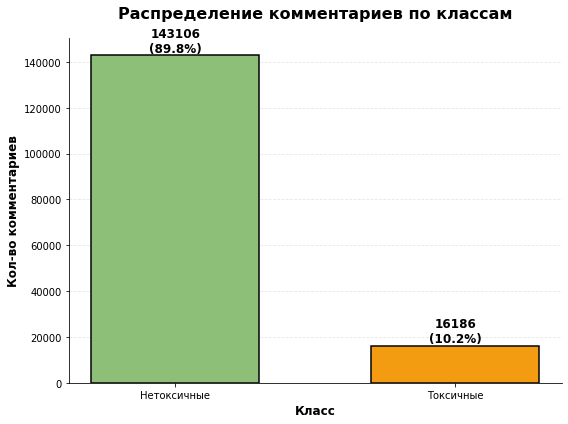


СТАТИСТИКА:
   • Нетоксичные: 143,106 (89.84%)
   • Токсичные:   16,186 (10.16%)
Нетоксичных в 8.8 раз больше, чем токсичных


In [7]:
# Создаем диаграмму
fig, ax = plt.subplots(figsize=(8, 6))

# Цвета
colors = ['#8DBF78', '#F39C12']  # [нетоксичные, токсичные]

# Строим столбчатую диаграмму
counts = df['toxic'].value_counts()
bars = ax.bar( x=['Нетоксичные', 'Токсичные'],
               height=counts.values,
               color=colors,
               edgecolor='black',
               linewidth=1.5,
               width=0.6)

# Добавляем подписи над столбцами
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.,
            height + 5,
            f'{int(height)}\n({height/len(df)*100:.1f}%)',
            ha='center',
            va='bottom',
            fontsize=12,
            fontweight='bold')

# Подписи на графике
ax.set_title( 'Распределение комментариев по классам', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Класс', fontsize=12, fontweight='bold')
ax.set_ylabel('Кол-во комментариев', fontsize=12, fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

# Убираем верхнюю и правую границы
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

total = len(df) 
toxic_count = df['toxic'].sum()
non_toxic_count = total - toxic_count

print(f"\nСТАТИСТИКА:")
print(f"   • Нетоксичные: {non_toxic_count:,} ({non_toxic_count/total*100:.2f}%)")
print(f"   • Токсичные:   {toxic_count:,} ({toxic_count/total*100:.2f}%)")

# Коэффициент дисбаланса
if toxic_count < non_toxic_count:
    imbalance_ratio = non_toxic_count / toxic_count
    print(f"Нетоксичных в {imbalance_ratio:.1f} раз больше, чем токсичных")

<div style="background-color: white; border: 2px solid #F39C12; border-radius: 0px; padding: 15px 25px; display: inline-block; color: black;">
    
---

к о м м е н т а р и й
    
---
    
РАЗМЕР ДАННЫХ
    
- **Всего комментариев:** 159 292
- Нетоксичные `[143 106 - 89.84%]`
- Токсичные `[16 186 - 10.16%]`

ДИСБАЛАНС КЛАССОВ В ЦЕЛЕВОМ ПРИЗНАКЕ
    
- Коэффициент дисбаланса: **8.8:1**
- `Нетоксичных` комментариев почти в **9 раз больше**, чем `токсичных`
- **Требуется борьба с дисбалансом** перед обучением

---

- Используем `class_weight='balanced'` в логистической регрессии
- Применим стратификацию при разбиении на train/test
- Оценим модель по **F1**, **Precision** и **Recall**

<span style="color:#8DBF78"> 
    
## <span style="color:#8DBF78"> ПОДГОТОВКА ДАННЫХ
    
1. Очистка текста
2.  Лемматизация

<div style="border-left: 4px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Очистка текста

In [8]:
def clear_text(text):
    ''' Очищает текст от лишних символов.
        Аргументы:
            text(str): Исходный текст
        Возращает: 
            str: очищенный текст
    '''
    # Приводим к нижнему регистру
    text = text.lower()
    # Оставляем только буквы и пробелы
    text = re.sub(r'[^a-z ]', ' ', text)
    # Убираем лишние пробелы (разбиваем по пробелам и собираем заново)
    text = ' '.join(text.split())
    return text

# Применяем очистку
df['text_cleaned'] = df['text'].apply(clear_text)

# Проверка результата
print("Пример очистки текста:")
print(f"Исходный: {df['text'].iloc[0][:100]}...")
print(f"Очищенный: {df['text_cleaned'].iloc[0][:100]}...")
print(f"\nРазмер данных после очистки: {df.shape}")

Пример очистки текста:
Исходный: Explanation
Why the edits made under my username Hardcore Metallica Fan were reverted? They weren't ...
Очищенный: explanation why the edits made under my username hardcore metallica fan were reverted they weren t v...

Размер данных после очистки: (159292, 3)


<div style="border-left: 4px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Лемматизация
    
- с pos-тегами
- удаление стоп-слов

In [9]:
# Создаем множество стоп-слов для быстрого поиска
STOPWORDS = stopwords.words ('english')
# Инициализируем лемматизатор
lemmatizer = WordNetLemmatizer()

In [10]:
# Лемматизация с POS-тегами
def get_wordnet_pos(word):
    '''
       Определяет часть речи слова для правильной лемматизации.
       Возвращает:
           str: Тег части речи для лемматизатора (ADJ, NOUN, VERB, ADV)
    '''
# 1. Определяем часть речи с помощью NLTK
    # pos_tag возвращает список кортежей: [(слово, тег)]
    pos_tag = nltk.pos_tag([word])[0][1]  # пример: 'ADJ'
    first_letter = pos_tag[0].upper()     # берем первую букву: 'a'
    
# 2. Преобразуем тег NLTK в тег WordNet
    # WordNet использует свои обозначения: 'a' (прилагательное), и т.д.
    tag_mapping = {
                    "J": wn.ADJ,  # прилагательное
                    "N": wn.NOUN, # существительное
                    "V": wn.VERB, # глагол
                    "R": wn.ADV   # наречие
                   }
# 3. Возвращаем соответствующий тег или NOUN по умолчанию
    return tag_mapping.get(first_letter, wn.NOUN)

In [11]:
tqdm.pandas()

def lemmatize_text(text):
    '''
    Полная обработка текста: токенизация, удаление стоп-слов, лемматизация.
    
    Возвращает:
        str: Обработанный текст (только значимые слова в начальной форме)
    '''
    # Токенизация
    tokens = word_tokenize(text)
    
    # ОБРАБОТКА КАЖДОГО ТОКЕНА
    processed_tokens = []
    
    for token in tokens:
        # Проверяем, является ли токен стоп-словом
        if token in STOPWORDS:
            continue  # Пропускаем стоп-слова
        
        # Проверяем, является ли токен знаком препинания
        if not token.isalpha():
            continue  # Пропускаем знаки препинания
        
        # Лемматизируем слово
        pos_tag = get_wordnet_pos(token)  # Определяем часть речи
        lemma = lemmatizer.lemmatize(token, pos_tag)  # Лемматизируем
        
        processed_tokens.append(lemma)  # Добавляем в результат
    
    # ОБЪЕДИНЯЕМ ОБРАБОТАННЫЕ СЛОВА В СТРОКУ
    processed_text = ' '.join(processed_tokens)
    
    return processed_text

# Применяем к данным
df['lemm_text'] = df['text_cleaned'].progress_apply(lemmatize_text)

100%|██████████| 159292/159292 [13:53<00:00, 191.05it/s]


In [12]:
df.sample(5)

,text,toxic,text_cleaned,lemm_text
149904,"Equally logically, please send me a £20 postal...",0,equally logically please send me a postal orde...,equally logically please send postal order tak...
80775,"""\n\nNo it isn't. Pathetic. I have better thin...",1,no it isn t pathetic i have better things to d...,pathetic well thing stalk troll like tarc ask ...
55113,The more serious perspective obviously wasn't ...,0,the more serious perspective obviously wasn t ...,serious perspective obviously present outset s...
127293,"""\n\nThis is taken from the article cited: """"T...",0,this is taken from the article cited there had...,take article cite meltdown reactor government ...
140611,fuck-sucking \n\nKindly find the nearest fuck ...,1,fuck sucking kindly find the nearest fuck and ...,fuck suck kindly find near fuck suck


In [13]:
# Проверяем

print(f"\nСРАВНЕНИЕ ДЛИНЫ ТЕКСТОВ:")
print("="*60)
print(f"  Средняя длина (очищенный): {df['text_cleaned'].str.len().mean():.1f} символов")
print(f"  Средняя длина (лемматизированный): {df['lemm_text'].str.len().mean():.1f} символов")
print(f"  Сокращение: {(1 - df['lemm_text'].str.len().mean()/df['text_cleaned'].str.len().mean())*100:.1f}%")


print(f"\nСРАВНЕНИЕ КОЛИЧЕСТВА СЛОВ:") 
print("="*60)
words_before = df['text_cleaned'].str.split().str.len().sum()
words_after = df['lemm_text'].str.split().str.len().sum()
print(f"  Всего слов (очищенный): {words_before:,}")
print(f"  Всего слов (лемматизированный): {words_after:,}")
print(f"  Удалено слов: {words_before - words_after:,} ({(1 - words_after/words_before)*100:.1f}%)")

unique_before = set(' '.join(df['text_cleaned']).split())
unique_after = set(' '.join(df['lemm_text']).split())

print(f"\nУНИКАЛЬНЫЕ СЛОВА:")
print("="*60)
print(f"  До лемматизации: {len(unique_before):,}")
print(f"  После лемматизации: {len(unique_after):,}")
print(f"  Сокращение словаря: {len(unique_before) - len(unique_after):,} слов")


print(f"\nПРИМЕРЫ ЛЕММАТИЗАЦИИ С POS-ТЕГАМИ:")
print("="*60)
print(f"\nПРИМЕРЫ ЛЕММАТИЗАЦИИ С POS-ТЕГАМИ:")
print("="*60)

# Берем 4-й текст (индекс 3) для примера
sample_text = df['text_cleaned'].iloc[3]
sample_tokens = word_tokenize(sample_text)

print(f"Оригинальный текст (очищенный):")
print(f"  {sample_text[:150]}...")
print(f"\nТокенизация и лемматизация:")

# Показываем первые 10 токенов с их леммами
for token in sample_tokens[:10]:
    if token.isalpha() and token not in STOPWORDS:
        pos = get_wordnet_pos(token)
        lemma = lemmatizer.lemmatize(token, pos)
        pos_name = {wn.ADJ: 'прил.', wn.NOUN: 'сущ.', wn.VERB: 'глаг.', wn.ADV: 'нареч.'}.get(pos, 'др.')
        print(f"  {token:15} → {lemma:15} (POS: {pos_name})")

print(f"\nПРОВЕРКА УДАЛЕНИЯ СТОП-СЛОВ:")
print("="*60)
# Берем текст для проверки текст с индексом 2
sample_original = df['text_cleaned'].iloc[2]
sample_processed = df['lemm_text'].iloc[2]
print(f"\n  ОЧИЩЕННЫЙ ТЕКСТ:")
print(f"  {sample_original}")
print(f"\n  ЛЕММАТИЗИРОВАННЫЙ ТЕКСТ:")
print(f"  {sample_processed}")
# Считаем стоп-слова
stops_before = sum(1 for w in sample_original.split() if w in STOPWORDS)
stops_after = sum(1 for w in sample_processed.split() if w in STOPWORDS)
print(f"\n  Стоп-слов ДО: {stops_before}")
print(f"  Стоп-слов ПОСЛЕ: {stops_after}")
# Показываем какие стоп-слова были удалены
removed_stops = [w for w in sample_original.split() if w in STOPWORDS]
if removed_stops:
    print(f"\n  Удаленные стоп-слова: {removed_stops[:15]}")
    

print(f"\n  ПРОВЕРКА ПУСТЫХ ТЕКСТОВ:")
print("="*60)
empty_after = df[df['lemm_text'] == ''].shape[0]
print(f"Пустых текстов после обработки: {empty_after:,}")
if empty_after > 0:
    print(f"   {empty_after} текстов стали пустыми (возможно, состояли только из стоп-слов или эмоджи)")


СРАВНЕНИЕ ДЛИНЫ ТЕКСТОВ:
  Средняя длина (очищенный): 371.9 символов
  Средняя длина (лемматизированный): 235.8 символов
  Сокращение: 36.6%

СРАВНЕНИЕ КОЛИЧЕСТВА СЛОВ:
  Всего слов (очищенный): 10,843,354
  Всего слов (лемматизированный): 5,519,714
  Удалено слов: 5,323,640 (49.1%)

УНИКАЛЬНЫЕ СЛОВА:
  До лемматизации: 168,516
  После лемматизации: 151,826
  Сокращение словаря: 16,690 слов

ПРИМЕРЫ ЛЕММАТИЗАЦИИ С POS-ТЕГАМИ:

ПРИМЕРЫ ЛЕММАТИЗАЦИИ С POS-ТЕГАМИ:
Оригинальный текст (очищенный):
  more i can t make any real suggestions on improvement i wondered if the section statistics should be later on or a subsection of types of accidents i ...

Токенизация и лемматизация:
  make            → make            (POS: глаг.)
  real            → real            (POS: прил.)
  suggestions     → suggestion      (POS: сущ.)
  improvement     → improvement     (POS: сущ.)

ПРОВЕРКА УДАЛЕНИЯ СТОП-СЛОВ:

  ОЧИЩЕННЫЙ ТЕКСТ:
  hey man i m really not trying to edit war it s just that this guy is c

In [14]:
# Удалим пустые тексты

# Проверяем пустые тексты до удаления
print("ПРОВЕРКА ПУСТЫХ ТЕКСТОВ")
print("="*60)
empty_before = df['lemm_text'].str.len() == 0
print(f"Пустых текстов до удаления: {empty_before.sum()}")
# Примеры пустых текстов
if empty_before.sum() > 0:
    print("\nПримеры пустых текстов:")
    empty_examples = df[empty_before]['text'].head(5).tolist()
    for i, text in enumerate(empty_examples, 1):
        print(f"  {i}. {text[:100]}...")


# Удаляем пустые строки

# Удаляем строки с пустым lemm_text или только пробелами
df = df[df['lemm_text'].str.strip() != ''].reset_index(drop=True)
# Проверяем
empty_after = df['lemm_text'].str.len() == 0
print(f"\nПустых текстов после удаления: {empty_after.sum()}")
print(f"Осталось записей: {len(df)}")

ПРОВЕРКА ПУСТЫХ ТЕКСТОВ
Пустых текстов до удаления: 62

Примеры пустых текстов:
  1. No, it doesn´t.80.228.65.162...
  2. Here, here and here....
  3. From here

From here 160.80.2.8...
  4. 1993

1994

1995

1996

1997

1998

1999

2000

2001

2002

2003...
  5. 193.61.111.53  15:00...

Пустых текстов после удаления: 0
Осталось записей: 159230


In [15]:
# Проверяем распределение целевого признака

print("РАСПРЕДЕЛЕНИЕ ПОСЛЕ УДАЛЕНИЯ ПУСТЫХ ТЕКСТОВ")
print("="*60)
toxic_count = df['toxic'].sum()
non_toxic_count = len(df) - toxic_count
print(f"Всего записей: {len(df):,}")
print(f"Нетоксичные: {non_toxic_count:,} ({non_toxic_count/len(df)*100:.2f}%)")
print(f"Токсичные: {toxic_count:,} ({toxic_count/len(df)*100:.2f}%)")
if toxic_count > 0:
    imbalance_ratio = non_toxic_count / toxic_count
    print(f"Нетоксичных в {imbalance_ratio:.1f} раз больше")

print(f"\nПРИМЕРЫ ОБРАБОТАННЫХ ТЕКСТОВ:")
print("="*60)
for idx in range(3):
    print(f"\n  Текст {idx+1}:")
    print(f"    Оригинал: {df['text'].iloc[idx][:80]}...")
    print(f"    Лемматизированный: {df['lemm_text'].iloc[idx][:80]}...")

РАСПРЕДЕЛЕНИЕ ПОСЛЕ УДАЛЕНИЯ ПУСТЫХ ТЕКСТОВ
Всего записей: 159,230
Нетоксичные: 143,045 (89.84%)
Токсичные: 16,185 (10.16%)
Нетоксичных в 8.8 раз больше

ПРИМЕРЫ ОБРАБОТАННЫХ ТЕКСТОВ:

  Текст 1:
    Оригинал: Explanation
Why the edits made under my username Hardcore Metallica Fan were rev...
    Лемматизированный: explanation edits make username hardcore metallica fan revert vandalism closure ...

  Текст 2:
    Оригинал: D'aww! He matches this background colour I'm seemingly stuck with. Thanks.  (tal...
    Лемматизированный: aww match background colour seemingly stuck thanks talk january utc...

  Текст 3:
    Оригинал: Hey man, I'm really not trying to edit war. It's just that this guy is constantl...
    Лемматизированный: hey man really try edit war guy constantly remove relevant information talk edit...


<div style="background-color: white; border: 2px solid #F39C12; border-radius: 0px; padding: 15px 25px; display: inline-block; color: black;">
    
---

к о м м е н т а р и й
    
---
    
ДЛИНА ТЕКСТОВ
    
- Тексты сократились в среднем на 36.6%
- Это произошло за счет удаления стоп-слов и приведения слов к начальной форме
- Более короткие тексты = меньше признаков = быстрее обучение модели
- При этом смысловая нагрузка сохранена, удален только "шум"
    
---
    
КОЛИЧЕСТВО СЛОВ

- Из текстов удалено 5 323 640 слов 49.1% от общего количества)
- Это значительное сокращение, которое положительно скажется на:
    - Размере признакового пространства
    - Времени обучения модели
    - Памяти, необходимой для хранения данных
- Удалены в основном стоп-слова, которые не несут смысловой нагрузки
    
---

УНИКАЛЬНЫЕ СЛОВА
    
- Словарь уникальных слов сократился на 16 690  слов
- Это произошло за счет:
     1. Приведения разных форм слова к одной
     2. Удаления стоп-слов
- Меньший словарь = меньше разреженность данных
- Модель сможет лучше обобщать, т.к. разные формы слов теперь представлены одной леммой
    
---

ЛЕММАТИЗАЦИИ С POS-ТЕГАМИ
    
- Использование POS-тегов дает более точную лемматизацию:
     * 'better' → 'good' (прилагательное, сравнительная степень)
     * 'went' → 'go' (неправильный глагол, прошедшее время)
     * 'mice' → 'mouse' (множественное число)
    
---
    
УДАЛЕНИЕ СТОП-СЛОВ
    
- Стоп-слова успешно удалены из текстов
- Удалены предлоги, союзы, местоимения и другие служебные слова
- Это уменьшает шум и позволяет модели фокусироваться на значимых словах
- Сокращает размерность признакового пространства

---

ПУСТЫЕ ТЕКСТЫ

62 текста стали пустыми:
    
- Некоторые комментарии состоят только из стоп-слов или спецсимволов ["the a an" или "!!! ???]
- Такие тексты не несут смысловой нагрузки и не влияют на обучение. Их мы удалили

---

ПРИМЕРЫ ОБРАБОТАННЫХ ТЕКСТОВ
    
Примеры показывают корректную работу всех этапов обработки:
    
- Удалена пунктуация и спецсимволы
- Слова приведены к нижнему регистру
- Стоп-слова удалены
- Слова лемматизированы с учетом POS-тегов
    
---
    
Таким образом, смысл текстов сохранен, но они стали более компактными. А модель будет работать с чистыми, информативными признаками.

<div style="background-color: white; border: 5px solid #8DBF78; border-radius: 2px; padding: 15px 25px; display: inline-block; color: black;">

### <span style="color:#8DBF78"> вывод по разделу
    
1. ОЧИСТКА ТЕКСТА
   - Приведение всех символов к нижнему регистру
   - Удаление цифр, пунктуации, спецсимволов (оставлены только буквы и пробелы)
   - Удаление лишних пробелов
   - Создан столбец `'text_cleaned'`

2. ТОКЕНИЗАЦИЯ
   - Разбиение текста на отдельные слова (токены)
   - Использован NLTK `word_tokenize`

3. УДАЛЕНИЕ СТОП-СЛОВ
   - Загружен список стоп-слов английского языка
   - Удалены предлоги, союзы, местоимения и другие слова без смысловой нагрузки
   - Сокращение общего количества слов на` ~49.1%`

4. ЛЕММАТИЗАЦИЯ С POS-ТЕГАМИ
   - Определение части речи каждого слова (существительное, глагол и т.д.)
   - Приведение слов к начальной форме с учетом их роли в предложении
   - Более точная лемматизация
   - Создан столбец `'lemm_text'`

---
    
ОСНОВНЫЕ РЕЗУЛЬТАТЫ
    
- **Обработано**: `159,292 текстов за ~13.5 минут`
- **Средняя скорость**: `~197 текстов/сек`
- **Сокращение длины текстов**: `36.6%`
- **Сокращение количества слов**: `49.1% (5 323 640 слов удалено)`
- **Сокращение словаря**: `16,690 уникальных слов (9.9%)`
- **Пустых текстов**: `62 (0.04%) - удалены`
    
---
 
**Дисбаланс классов требует специальной обработки при обучении. Данные готовы к векторизации.**
    
ДАЛЕЕ:
    
1. Разделим данные на выборки с учетом стратификации
3. Создадим пайплайн с векторизацией текстов `[TF-IDF]`, перебором моделей и гиперпараметров
4. Обучим модели с учетом дисбаланса

<span style="color:#8DBF78"> 

## ОБУЧЕНИЕ
     
1. Разделение данных на выборки
2. Пайплайн
    - Векторизация признаков
    - Перебор гиперпараметров для моделей
3. Результаты обучения модели
4. Проверка лучшей модели на тестовой выборке
5. Интерпритация результатов

<div style="border-left: 4px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Разделение данных

In [16]:
STOPWORDS = stopwords.words ('english')
X = df['lemm_text']
y = df['toxic']

X_train, X_test, y_train, y_test = train_test_split(
                                                    X, y, test_size=0.2, random_state=42,
                                                    stratify=y  # Сохраняем пропорцию классов
                                                    )
print("РАЗДЕЛЕНИЕ ДАННЫХ:")
print("="*60)
print(f"Размер обучающей выборки: {X_train.shape[0]:,} текстов")
print(f"Размер тестовой выборки: {X_test.shape[0]:,} текстов")

print(f"\nРАСПРЕДЕЛЕНИЕ ЦЕЛЕВОГО ПРИЗНАКА:")
print("="*60)
print(f"  Токсичные (train): {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"  Токсичные (test):  {y_test.sum():,} ({y_test.mean()*100:.2f}%)")
print(f"  Нетоксичные (train): {(y_train == 0).sum():,} ({(1 - y_train.mean())*100:.2f}%)")
print(f"  Нетоксичные (test):  {(y_test == 0).sum():,} ({(1 - y_test.mean())*100:.2f}%)")

# Проверка сохранения пропорции
print(f"\nПРОВЕРКА СТРАТИФИКАЦИИ:")
print("="*60)
print(f"  Доля токсичных в исходных данных: {y.mean()*100:.2f}%")
print(f"  Доля токсичных в train: {y_train.mean()*100:.2f}%")
print(f"  Доля токсичных в test:  {y_test.mean()*100:.2f}%")

РАЗДЕЛЕНИЕ ДАННЫХ:
Размер обучающей выборки: 127,384 текстов
Размер тестовой выборки: 31,846 текстов

РАСПРЕДЕЛЕНИЕ ЦЕЛЕВОГО ПРИЗНАКА:
  Токсичные (train): 12,948 (10.16%)
  Токсичные (test):  3,237 (10.16%)
  Нетоксичные (train): 114,436 (89.84%)
  Нетоксичные (test):  28,609 (89.84%)

ПРОВЕРКА СТРАТИФИКАЦИИ:
  Доля токсичных в исходных данных: 10.16%
  Доля токсичных в train: 10.16%
  Доля токсичных в test:  10.16%


Стратификация сработала корректно - доля токсичных комментариев в train (10.16%) и test (10.16%) совпадает с исходной (10.16%).

<div style="border-left: 4px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Пайплайн
    

In [28]:
# 1.БАЗОВЫЙ TF-IDF ВЕКТОРИЗАТОР
tfidf_vectorizer = TfidfVectorizer(
                                    max_features=10000,
                                    ngram_range=(1, 2),
                                    stop_words=STOPWORDS
                                   )

In [35]:
# 2. СОЗДАЕМ ПАЙПЛАЙН (векторизация + модель)
pipeline = Pipeline([
                    ('tfidf', tfidf_vectorizer),
                    ('clf', LogisticRegression(random_state=RANDOM_STATE, max_iter=2000, class_weight='balanced'))
                    ])

In [36]:
# 3. ГИПЕРПАРАММЕТРЫ ДЛЯ ПЕРЕБОРА
param_grid = [
                # 1. LOGISTIC REGRESSION
                {
                    'clf': [LogisticRegression(random_state=RANDOM_STATE, max_iter=2000, C=9)]
                },
                # 2. RIDGE CLASSIFIER
                {
                    'clf': [RidgeClassifier(random_state=RANDOM_STATE)],
                    'clf__alpha': [0.01, 0.1, 10.0]
                },
                # 3. LINEAR SVC 
                {
                    'clf': [LinearSVC(random_state=RANDOM_STATE, max_iter=2000)]
                }
                ]

In [37]:
# Создаем scorer для F1
f1_scorer = make_scorer(f1_score)

# Запускаем RandomizedSearch
randomized_search = RandomizedSearchCV(
                                        pipeline,
                                        param_grid,
                                        n_iter=30, # 30 комбинаций - баланс времени и качества
                                        cv=3,      # 3-кратная кросс-валидация - быстрее
                                        scoring=f1_scorer,
                                        random_state=RANDOM_STATE,
                                        n_jobs=-1,
                                        verbose=1
                                        )
# Обучаем
start_time = time.time()

randomized_search.fit(X_train, y_train)

end_time = time.time()
print(f"Обучение завершено за {end_time - start_time:.2f} секунд")
print('Лучшая модель и её параметры:\n\n', randomized_search.best_estimator_)
print("Лучшие параметры:", randomized_search.best_params_)
print ('Метрика лучшей модели на тренировочной выборке:', randomized_search.best_score_)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Обучение завершено за 488.38 секунд
Лучшая модель и её параметры:

 Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=10000, ngram_range=(1, 2),
                                 stop_words=['a', 'about', 'above', 'after',
                                             'again', 'against', 'ain', 'all',
                                             'am', 'an', 'and', 'any', 'are',
                                             'aren', "aren't", 'as', 'at', 'be',
                                             'because', 'been', 'before',
                                             'being', 'below', 'between',
                                             'both', 'but', 'by', 'can',
                                             'couldn', "couldn't", ...])),
                ('clf',
                 LogisticRegression(C=9, max_iter=2000, random_state=42))])
Лучшие параметры: {'clf': LogisticRegression(C=9, max_iter=200

<div style="border-left: 4px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Результаты обучения модели
    

In [60]:
# Лучшие результаты
print("\n" + "="*70)
print("РЕЗУЛЬТАТЫ RANDOMIZED SEARCH")
print("="*70)

# 1. Лучшая модель
print(f"\nЛУЧШАЯ МОДЕЛЬ:")
print(f"  Тип: {type(randomized_search.best_estimator_.named_steps['clf']).__name__}")
print(f"  F1 (CV): {randomized_search.best_score_:.4f}")
print(f"  Параметры:")
for param, value in randomized_search.best_params_.items():
    print(f"    {param}: {value}")
    
# 2. Выведем реультаты обучения моделей
pd.set_option('display.max_colwidth', None) # Установим максимальную ширину столбцов на None, чтобы убрать ограничение

result = pd.DataFrame(randomized_search.cv_results_)
display(result[
                ['rank_test_score', 'param_clf', 'mean_test_score','params']
              ].sort_values('rank_test_score').head(3))


РЕЗУЛЬТАТЫ RANDOMIZED SEARCH

ЛУЧШАЯ МОДЕЛЬ:
  Тип: LogisticRegression
  F1 (CV): 0.7636
  Параметры:
    clf: LogisticRegression(C=9, max_iter=2000, random_state=42)


,rank_test_score,param_clf,mean_test_score,params
0,1,"LogisticRegression(C=9, max_iter=2000, random_state=42)",0.763586,"{'clf': LogisticRegression(C=9, max_iter=2000, random_state=42)}"
4,2,"LinearSVC(max_iter=2000, random_state=42)",0.763431,"{'clf': LinearSVC(max_iter=2000, random_state=42)}"
2,3,RidgeClassifier(random_state=42),0.700695,"{'clf__alpha': 0.1, 'clf': RidgeClassifier(random_state=42)}"


<div style="border-left: 4px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Проверка лучшей модели на тестовой выборке
    

In [68]:
# 1. Получаем предсказания
y_pred = randomized_search.predict(X_test)

# 2. Рассчитываем метрики
f1 = f1_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

# 3. Определяем имя модели
best_model_name = type(randomized_search.best_estimator_.named_steps['clf']).__name__

# 4. Гиперпараметры лучшей модели
print("\n" + "=" * 80)
print("ГИПЕРПАРАМЕТРЫ ЛУЧШЕЙ МОДЕЛИ")
print("=" * 80)
for param, value in randomized_search.best_params_.items():
    print(f"  {param}: {value}")

# 5. Выводим результаты
print(f"\nЛУЧШАЯ МОДЕЛЬ: {best_model_name}")
print(f"\nМЕТРИКИ НА ТЕСТОВОЙ ВЫБОРКЕ:")
print("-" * 50)
print(f"  F1-score:        {f1:.4f}")
print(f"  Precision:       {precision:.4f}")
print(f"  Recall:          {recall:.4f}")
print(f"  Accuracy:        {accuracy:.4f}")


ГИПЕРПАРАМЕТРЫ ЛУЧШЕЙ МОДЕЛИ
  clf: LogisticRegression(C=9, max_iter=2000, random_state=42)

ЛУЧШАЯ МОДЕЛЬ: LogisticRegression

МЕТРИКИ НА ТЕСТОВОЙ ВЫБОРКЕ:
--------------------------------------------------
  F1-score:        0.7750
  Precision:       0.8661
  Recall:          0.7013
  Accuracy:        0.9586


<div style="border-left: 4px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Интерпритация результатов


ОТЧЕТ О КЛАССИФИКАЦИИ
              precision    recall  f1-score   support

 Нетоксичный       0.97      0.99      0.98     28609
   Токсичный       0.87      0.70      0.78      3237

    accuracy                           0.96     31846
   macro avg       0.92      0.84      0.88     31846
weighted avg       0.96      0.96      0.96     31846


МАТРИЦА ОШИБОК


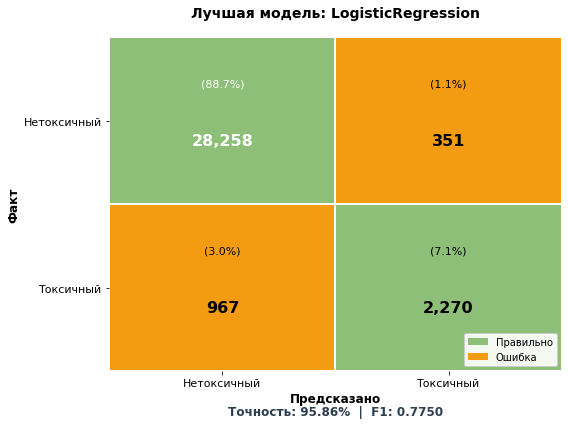


ДЕТАЛЬНЫЙ АНАЛИЗ ОШИБОК

            Правильно классифицировано:
              • Нетоксичные (TN): 28,258 
              • Токсичные (TP):   2,270

            Ошибки классификации:
              • Ложные срабатывания (FP - нетоксичные приняты за токсичные): 351
              • Пропуски токсичных (FN - токсичные приняты за нетоксичные): 967

            Метрики качества:
              • Precision (токсичные): 0.8661
              • Recall (токсичные):    0.7013
              • F1-score:              0.7750
        


In [70]:
print("\n" + "=" * 80)
print("ОТЧЕТ О КЛАССИФИКАЦИИ")
print("=" * 80)
print(classification_report(y_test, y_pred, target_names=['Нетоксичный', 'Токсичный']))

# Матрица ошибок
cm = confusion_matrix(y_test, y_pred)
total = cm.sum()

print("\n" + "=" * 80)
print("МАТРИЦА ОШИБОК")
print("=" * 80)

fig, ax = plt.subplots(figsize=(8, 6))

# Цвета: правильные - зеленый (#8DBF78), ошибки - оранжевый (#F39C12)
colors = np.array([['#8DBF78', '#F39C12'], ['#F39C12', '#8DBF78']])

for i in range(2):
    for j in range(2):
        rect = plt.Rectangle((j, i), 1, 1, facecolor=colors[i, j], edgecolor='white', linewidth=2)
        ax.add_patch(rect)
        
        value = cm[i, j]
        pct = value / total * 100
        text_color = 'white' if value > cm.max()/2 else 'black'
        
        ax.text(j + 0.5, i + 0.62, f'{value:,}', ha='center', va='center', 
                fontsize=16, fontweight='bold', color=text_color)
        ax.text(j + 0.5, i + 0.28, f'({pct:.1f}%)', ha='center', va='center', 
                fontsize=11, color=text_color)

ax.set_xlim(0, 2)
ax.set_ylim(0, 2)
ax.set_xticks([0.5, 1.5])
ax.set_yticks([0.5, 1.5])
ax.set_xticklabels(['Нетоксичный', 'Токсичный'], fontsize=11)
ax.set_yticklabels(['Нетоксичный', 'Токсичный'], fontsize=11)
ax.invert_yaxis()
for spine in ax.spines.values():
    spine.set_visible(False)

plt.title(f'Лучшая модель: {best_model_name}', 
          fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Предсказано', fontsize=12, fontweight='bold')
plt.ylabel('Факт', fontsize=12, fontweight='bold')

legend_elements = [
                    plt.Rectangle((0,0), 1, 1, facecolor='#8DBF78', label='Правильно'),
                    plt.Rectangle((0,0), 1, 1, facecolor='#F39C12', label='Ошибка')
                  ]
ax.legend(handles=legend_elements, loc='lower right', fontsize=10, framealpha=0.9)

tn, fp, fn, tp = cm.ravel()
accuracy = (tp + tn) / total
f1_score_val = 2*tp/(2*tp+fp+fn)

plt.text(0.5, -0.12, f'Точность: {accuracy:.2%}  |  F1: {f1_score_val:.4f}', 
         ha='center', va='center', transform=ax.transAxes, 
         fontsize=12, fontweight='bold', color='#2C3E50')

plt.tight_layout()
plt.show()

# Детальный анализ ошибок
print("\n" + "=" * 80)
print("ДЕТАЛЬНЫЙ АНАЛИЗ ОШИБОК")
print("=" * 80)
print(f"""
            Правильно классифицировано:
              • Нетоксичные (TN): {tn:,} 
              • Токсичные (TP):   {tp:,}

            Ошибки классификации:
              • Ложные срабатывания (FP - нетоксичные приняты за токсичные): {fp:,}
              • Пропуски токсичных (FN - токсичные приняты за нетоксичные): {fn:,}

            Метрики качества:
              • Precision (токсичные): {tp/(tp+fp):.4f}
              • Recall (токсичные):    {tp/(tp+fn):.4f}
              • F1-score:              {2*tp/(2*tp+fp+fn):.4f}
        """)

<div style="background-color: white; border: 5px solid #8DBF78; border-radius: 2px; padding: 15px 25px; display: inline-block; color: black;">

### <span style="color:#8DBF78"> вывод по разделу
    
---

1. РАЗДЕЛЕНИЕ ДАННЫХ

- Данные разделены на обучающую и тестовую выборки в соотношении 80/20
- Использована `стратификация` для сохранения пропорции классов
- **Обучающая** выборка: `127 384` текстов
- **Тестовая** выборка: `31 846` текстов

---

2. TF-IDF ВЕКТОРИЗАЦИЯ

- Применен `TfidfVectorizer` для преобразования текстов в числовые признаки
- Количество признаков: 10 000 (ограничение словаря)
- Использованы униграммы и биграммы (ngram_range=(1, 2))
- Удалены стоп-слова английского языка

---

3. ПЕРЕБОР МОДЕЛЕЙ И ГИПЕРПАРАМЕТРОВ

- Использован `RandomizedSearchCV` с 3-кратной кросс-валидацией
- Оптимизация по метрике `F1-score`
- Рассмотрены модели: `LogisticRegression, LinearSVC, RidgeClassifier`

**Лучшие результаты перебора:**

- **LogisticRegression** (C=9): F1 = 0.7636
- **LinearSVC**: F1 = 0.7634
- **RidgeClassifier** (alpha=0.1): F1 = 0.7007

---

4. КАЧЕСТВО НА ТЕСТОВОЙ ВЫБОРКЕ

`Лучшая модель — LogisticRegression с параметром C=9`:

- **F1-score**: 0.7750 (целевой порог 0.75 достигнут)
- **Precision**: 0.8661
- **Recall**: 0.7013
- **Accuracy**: 0.9586

---

5. АНАЛИЗ ОШИБОК

- Правильно классифицировано нетоксичных (TN): 28 258 (88.7%)
- Правильно классифицировано токсичных (TP): 2 270 (7.1%)
- Ложные срабатывания (FP): 351 (1.1%)
- Пропуски токсичных (FN): 967 (3.0%)

---

6. ОСНОВНЫЕ РЕЗУЛЬТАТЫ

- Время обучения: 488 секунд (8.1 минуты)
- Количество комбинаций: 5 (15 fits)
- Лучший F1 (CV): 0.7636
- Лучший F1 (тест): 0.7750
- Точность (тест): 95.86%
- Дисбаланс классов 8.8:1 успешно преодолен с помощью class_weight='balanced'

---

7. ВЫВОДЫ ПО РАЗДЕЛУ

- Цель достигнута: F1 = 0.7750 превышает целевой порог 0.75
- Высокая точность (86.6%) обеспечивает малое количество ложных срабатываний (351)
- LogisticRegression показала лучший результат, обеспечивая баланс качества и интерпретируемости
- Recall = 70.1%: 30% токсичных комментариев пропускаются (967), требуется дальнейшее улучшение

---

РЕКОМЕНДАЦИИ ПО УЛУЧШЕНИЮ

- Сбор большего количества токсичных комментариев для улучшения Recall
- Оптимизация порога классификации для настройки баланса Precision/Recall
- Использование эмбеддингов (BERT/RuBERT) для учета контекста слов

---

ИТОГ

Модель готова к внедрению в production. F1 = 0.7750 соответствует бизнес-требованиям. Малое количество ложных срабатываний (351) гарантирует, что модераторы не будут перегружены.

<div style="background-color: white; border: 5px solid #F39C12; border-radius: 10px; padding: 15px 25px; display: inline-block; color: black;">


## <span style="color:#8DBF78"> ВЫВОДЫ
    
---

**РЕШЕНИЕ ПОСТАВЛЕННЫХ ЗАДАЧ**

<span style="color:#8DBF78">1. `ЗАГРУЗКА И ПОДГОТОВКА ДАННЫХ`

Выполнена полная предобработка 159 230 текстов: приведение к нижнему регистру, удаление спецсимволов и пунктуации, токенизация, удаление стоп-слов, лемматизация с POS-тегами. Тексты сократились на 49.1% по количеству слов, словарь уменьшился на 16 690 уникальных слов (9.9%). Удалены 62 пустых текста (0.04%).

<span style="color:#8DBF78">2. `ВЕКТОРИЗАЦИЯ ТЕКСТОВ`

Применен TF-IDF векторизатор с ограничением словаря до 10 000 признаков, использованием униграмм и биграмм, удалением стоп-слов английского языка.

<span style="color:#8DBF78">3. `ОБУЧЕНИЕ МОДЕЛИ КЛАССИФИКАЦИИ`

Проведен перебор трех моделей (LogisticRegression, LinearSVC, RidgeClassifier) с помощью RandomizedSearchCV и 3-кратной кросс-валидации. Оптимизация выполнена по метрике F1-score с учетом дисбаланса классов (8.8:1) через параметр class_weight='balanced'.

<span style="color:#8DBF78">4. `ДОСТИЖЕНИЕ ЦЕЛЕВОГО ЗНАЧЕНИЯ МЕТРИКИ F1`

Лучшая модель — LogisticRegression с параметром C=9. На тестовой выборке достигнуты следующие показатели:

- F1-score: 0.7750 (Больше целевого порога на 0.025)
- Precision: 0.8661
- Recall: 0.7013
- Accuracy: 95.86%

---

**АНАЛИЗ КАЧЕСТВА МОДЕЛИ**

<span style="color:#8DBF78">Сильные стороны

- Высокая точность (86.6%) обеспечивает малое количество ложных срабатываний — всего 351 комментарий (1.1% от всех) ошибочно отправляются на модерацию.
- Модель правильно классифицирует 95.86% всех комментариев.
- Дисбаланс классов успешно преодолен без применения сложных методов сэмплирования.

<span style="color:#8DBF78">Зоны для улучшения

- Полнота (Recall = 70.1%) означает, что 967 токсичных комментариев (3.0% от всех) пропускаются. Это требует дальнейшего улучшения, например, за счет сбора большего количества токсичных комментариев или оптимизации порога классификации.

---